# Chapitre 1 - Cours 3 : cloud ou auto-hébergement

Deuxième grand compromis du chapitre : faut-il faire tourner soi-même ses systèmes de
données, ou les louer à un fournisseur de cloud ? La question est d'abord économique et
organisationnelle, mais le cloud a aussi transformé la **manière de construire** les
systèmes de données : stockage objet, séparation du stockage et du calcul,
multi-location. Ce notebook couvre la section *Cloud Versus Self-Hosting* : *Pros and
Cons of Cloud Services*, *Cloud Native System Architecture* (*Layering of cloud
services*, *Separation of storage and compute*) et *Operations in the Cloud Era*.

**Plan.**

1. Construire ou acheter, opérer ou externaliser : le spectre des choix.
2. Le coût : un modèle de coût total selon la taille et la variabilité de la charge.
3. Le contrôle : ce que l'on cède au fournisseur, et le prix de la sortie.
4. L'architecture cloud native : empilement des services et ordres de grandeur des
   couches de stockage.
5. Séparer stockage et calcul : disques éphémères, disques virtuels, caches.
6. La multi-location : mutualisation et voisins bruyants.
7. L'exploitation à l'ère du cloud : de la planification de capacité à la planification
   financière.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import architecture as ar
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## 1. Construire ou acheter, opérer ou externaliser (section *Cloud Versus Self-Hosting*)

Pour toute activité, une organisation se demande si elle la fait elle-même ou si elle
l'achète. Règle empirique citée par le livre : ce qui relève du **cœur de métier** ou d'un
**avantage concurrentiel** se fait en interne ; ce qui est banal, routinier, se confie à
un fournisseur (presque personne ne fabrique ses propres processeurs). Pour le logiciel,
deux décisions se superposent : **qui écrit** le logiciel, et **qui le déploie et
l'exploite**.

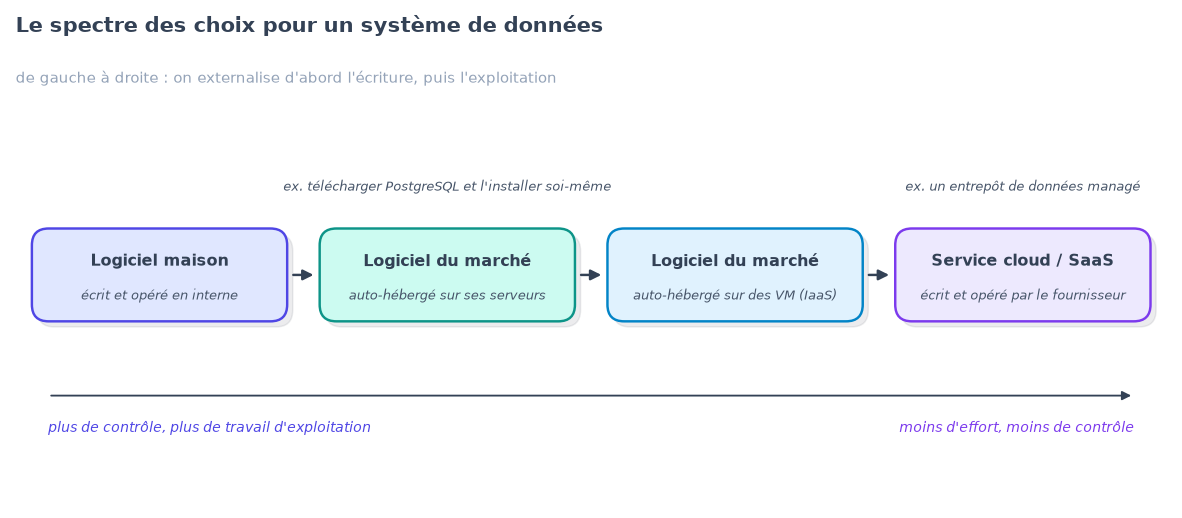

In [2]:
d = Diagram(12.5, 4.4, title="Le spectre des choix pour un système de données",
            subtitle="de gauche à droite : on externalise d'abord l'écriture, puis l'exploitation")
specs = [("custom", "Logiciel maison", "écrit et opéré en interne", INDIGO),
         ("onprem", "Logiciel du marché", "auto-hébergé sur ses serveurs", TEAL),
         ("iaas", "Logiciel du marché", "auto-hébergé sur des VM (IaaS)", SKY),
         ("saas", "Service cloud / SaaS", "écrit et opéré par le fournisseur", VIOLET)]
for i, (k, t, sub, c) in enumerate(specs):
    d.box(k, 1.6 + i * 3.1, 2.5, t, sub=sub, color=c, w=2.75, h=1.0)
for a, b in zip(specs, specs[1:]):
    d.arrow(a[0], b[0])
d.line([(0.4, 1.2), (12.1, 1.2)], color=SLATE, style="solid")
d.note(0.4, 0.85, "plus de contrôle, plus de travail d'exploitation", ha="left", color=INDIGO)
d.note(12.1, 0.85, "moins d'effort, moins de contrôle", ha="right", color=VIOLET)
d.note(4.7, 3.45, "ex. télécharger PostgreSQL et l'installer soi-même", fontsize=8.5)
d.note(10.9, 3.45, "ex. un entrepôt de données managé", fontsize=8.5)
d.show()

Au milieu du spectre, on trouve le logiciel du marché (libre ou commercial) qu'on
**auto-héberge** : sur son propre matériel (« on premises », même si le serveur est dans
une baie louée), ou sur une machine virtuelle louée à un cloud (*infrastructure as a
service*, IaaS). Il existe des points intermédiaires (un logiciel libre modifié, par
exemple). Le choix de l'outillage de déploiement (orchestrateur comme Kubernetes) est
laissé de côté par le livre : il pèse moins sur l'architecture des données.

> **À retenir.** Deux questions distinctes : qui écrit le logiciel, et qui l'exploite.
> On garde en interne ce qui fait la différence, on achète le reste.

## 2. Le coût : prévisible ou variable (section *Pros and Cons of Cloud Services*)

Les fournisseurs promettent économies et rapidité. Le livre nuance : si l'on sait **déjà**
exploiter le système, et si la charge est **prévisible** (le nombre de machines nécessaires
varie peu), acheter ses machines est souvent moins cher. À l'inverse, apprendre à exploiter
un système qu'on ne connaît pas, recruter et former une équipe, coûte cher ; et quand la
charge **varie beaucoup**, une flotte dimensionnée pour le pic reste inactive la plupart
du temps, alors qu'un cloud permet de rendre les ressources inutilisées.

**Un modèle de coût total.** On compare trois options pour servir une charge horaire
(fonction `ar.load_profile` : cycle quotidien de moyenne et de pic choisis) :

- **auto-hébergé** : serveurs achetés, dimensionnés pour le pic avec 30 % de marge,
  amortis à 250 € par mois et par serveur (achat, hébergement, électricité), plus
  10 000 € par mois d'exploitation (une part d'équipe) ;
- **cloud, flotte fixe** : même dimensionnement, mais en instances à 1,00 € l'heure
  (730 € par mois : près de trois fois le coût d'un serveur possédé), et seulement 3 000 € par mois
  d'exploitation ;
- **cloud, élastique** : on paie chaque heure le nombre d'instances nécessaire.

Les chiffres sont des ordres de grandeur plausibles, pas des tarifs : ce qui compte, ce
sont les **formes** des courbes. Un serveur traite 1 000 requêtes par seconde.

taux d'utilisation de la flotte fixe : 18%


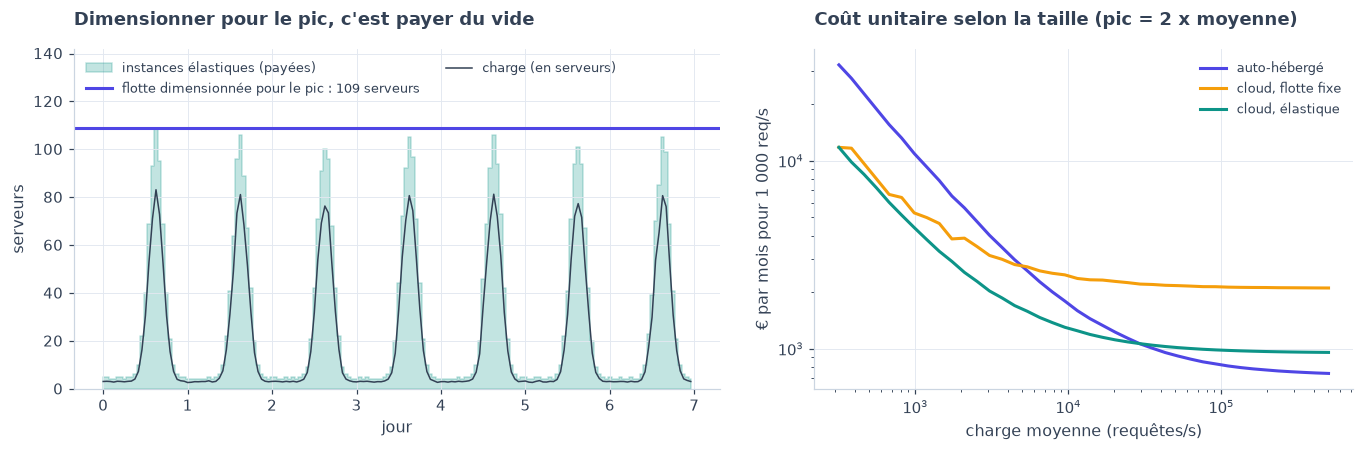

In [3]:
CAP, SRV_M, OPS_SELF, INST_H, OPS_CLOUD = 1000.0, 250.0, 10_000.0, 1.0, 3_000.0


def three_costs(mean, peak_ratio, seed=0):
    load = ar.load_profile(24 * 28, mean=mean, peak_ratio=peak_ratio, seed=seed)
    return (ar.cost_self_hosted(load, CAP, SRV_M, OPS_SELF),
            ar.cost_cloud(load, CAP, INST_H, OPS_CLOUD, autoscale=False),
            ar.cost_cloud(load, CAP, INST_H, OPS_CLOUD, autoscale=True))


load = ar.load_profile(24 * 7, mean=20_000, peak_ratio=4, seed=1)
n_auto = ar.servers_needed(load, CAP, 0.3)
n_peak = ar.servers_needed(load.max(), CAP, 0.3).item()
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
h = np.arange(load.size) / 24
ax.fill_between(h, n_auto, step="mid", color=TEAL, alpha=0.25, label="instances élastiques (payées)")
ax.axhline(n_peak, color=INDIGO, lw=2, label=f"flotte dimensionnée pour le pic : {n_peak} serveurs")
ax.plot(h, load / CAP, color=SLATE, lw=1, label="charge (en serveurs)")
ax.set_xlabel("jour"); ax.set_ylabel("serveurs"); ax.set_ylim(0, n_peak * 1.3)
ax.set_title("Dimensionner pour le pic, c'est payer du vide")
ax.legend(loc="upper left", fontsize=8.5, ncol=2)
print(f"taux d'utilisation de la flotte fixe : {load.mean() / (n_peak * CAP):.0%}")

means = np.logspace(2.5, 5.7, 40)
costs = np.array([three_costs(m, 2) for m in means])
ax = axes[1]
for j, (lab, c) in enumerate([("auto-hébergé", INDIGO), ("cloud, flotte fixe", AMBER), ("cloud, élastique", TEAL)]):
    ax.loglog(means, costs[:, j] / (means / 1000), color=c, label=lab)
ax.set_xlabel("charge moyenne (requêtes/s)"); ax.set_ylabel("€ par mois pour 1 000 req/s")
ax.set_title("Coût unitaire selon la taille (pic = 2 x moyenne)")
ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

À gauche, la flotte fixe n'est utilisée qu'à moins de 20 % en moyenne : l'élasticité du cloud
récupère cette marge. À droite, le coût par unité de charge raconte l'histoire du livre.
À **petite échelle**, le coût fixe d'exploitation domine : le cloud (moins de travail
d'exploitation) l'emporte nettement. À **grande échelle**, le prix par machine domine : le
cloud en flotte fixe devient l'option la plus chère, et l'auto-hébergement finit par
passer sous le cloud élastique (vers quelques dizaines de milliers de requêtes par seconde
pour ce rapport pic/moyenne de 2). Où se situe le point de bascule ? Il dépend surtout de la
**variabilité** de la charge : balayons la charge moyenne et le rapport pic/moyenne.

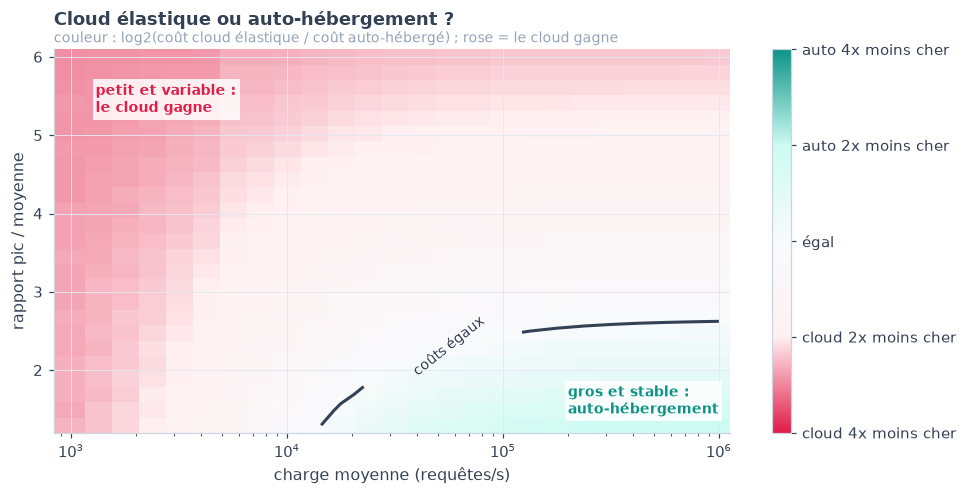

In [4]:
peaks = np.linspace(1.3, 6, 25)
means2 = np.logspace(3, 6, 25)
ratio = np.array([[three_costs(m, p)[2] / three_costs(m, p)[0] for m in means2] for p in peaks])
fig, ax = plt.subplots(figsize=(9, 4.6))
im = ax.pcolormesh(means2, peaks, np.log2(ratio), cmap="ddia_div", vmin=-2, vmax=2, shading="auto")
cs = ax.contour(means2, peaks, ratio, levels=[1.0], colors=[SLATE], linewidths=2)
ax.clabel(cs, fmt={1.0: "coûts égaux"}, fontsize=9)
ax.set_xscale("log")
ax.set_xlabel("charge moyenne (requêtes/s)"); ax.set_ylabel("rapport pic / moyenne")
cb = plt.colorbar(im, ax=ax); cb.set_ticks([-2, -1, 0, 1, 2])
cb.set_ticklabels(["cloud 4x moins cher", "cloud 2x moins cher", "égal", "auto 2x moins cher", "auto 4x moins cher"])
ax.set_title("Cloud élastique ou auto-hébergement ?")
subtitle(ax, "couleur : log2(coût cloud élastique / coût auto-hébergé) ; rose = le cloud gagne")
box = dict(fc="white", ec="none", alpha=0.85, pad=2)
ax.text(1.3e3, 5.3, "petit et variable :\nle cloud gagne", color=ROSE, fontsize=9, fontweight="bold", bbox=box)
ax.text(2e5, 1.45, "gros et stable :\nauto-hébergement", color=TEAL, fontsize=9, fontweight="bold", bbox=box)
plt.tight_layout(); plt.show()

La frontière confirme les deux critères du livre : une charge **petite** (l'exploitation
coûte cher relativement) ou **très variable** (la flotte fixe dort) favorise le cloud ;
une charge **grosse et stable** favorise l'auto-hébergement, à condition d'avoir les
compétences. Le cas typique de charge très variable est l'**analytique** : une requête
interactive sur un gros jeu de données veut beaucoup de machines pendant quelques
secondes, puis plus rien jusqu'à la suivante. Plus on la veut rapide, plus la charge
devient pointue : par exemple 200 machines pendant 30 secondes, dix fois par heure, soit
une utilisation moyenne de 8 % d'une flotte qui serait dimensionnée pour ces pointes.

Deux autres arguments jouent dans les deux sens : un fournisseur qui exploite le même
service pour des milliers de clients accumule une **expertise** qu'aucune équipe interne
n'égale ; mais il ne **personnalisera** pas son service pour votre charge particulière.

> **À retenir.** Le cloud gagne quand la charge est petite ou très variable (on rend
> ce qu'on n'utilise pas, on n'entretient pas d'équipe) ; l'auto-hébergement gagne quand
> elle est grosse, stable, et qu'on sait exploiter le système.

## 3. Le contrôle : ce que l'on cède (section *Pros and Cons of Cloud Services*)

Le plus gros défaut d'un service cloud, selon le livre, est l'**absence de contrôle** :

- une fonctionnalité manque ? On ne peut que la demander poliment au fournisseur ;
- le service tombe en panne ? On ne peut qu'attendre ;
- un bogue ou un problème de performance ? Sans accès aux métriques du système
  d'exploitation ni aux journaux du serveur, le diagnostic est difficile ;
- le service ferme, devient trop cher ou change dans le mauvais sens ? Faute de pouvoir
  garder l'ancienne version, il faut **migrer**, d'autant plus cher que les API ne sont
  pas standard : c'est l'**enfermement propriétaire** (« vendor lock-in ») ;
- un conflit politique entre pays peut couper l'accès au service (sanctions) ;
- il faut faire confiance au fournisseur pour la sécurité des données, ce qui complique
  la conformité réglementaire.

**Le prix de la sortie.** Un ressort concret de l'enfermement est la gravité des données :
les sortir d'un cloud coûte des frais de transfert sortant (« egress », de l'ordre de
0,05 à 0,09 $ par Go dans les grilles publiques) et du temps. Calculons-le.

In [5]:
rows = []
for label, size_gb in [("1 To", 1e3), ("100 To", 1e5), ("1 Po", 1e6), ("10 Po", 1e7)]:
    rows.append({"volume": label,
                 "frais de sortie (k$, à 0,07 $/Go)": size_gb * 0.07 / 1e3,
                 "transfert à 1 Gb/s (jours)": size_gb * 8 / 1 / 86400,
                 "transfert à 10 Gb/s (jours)": size_gb * 8 / 10 / 86400})
pd.DataFrame(rows).set_index("volume")

,"frais de sortie (k$, à 0,07 $/Go)",transfert à 1 Gb/s (jours),transfert à 10 Gb/s (jours)
volume,,,
1 To,0.07,0.093,0.009
100 To,7.00,9.259,0.926
1 Po,70.00,92.593,9.259
10 Po,700.00,925.926,92.593


Un pétaoctet coûte environ 70 000 $ et neuf jours de transfert à 10 Gb/s (soutenus en
continu, ce qui est optimiste) ; dix pétaoctets, trois mois. Ces chiffres ne comptent
même pas le plus cher : réécrire le code qui dépend d'API propriétaires. Malgré ces
risques, de plus en plus d'applications naissent dans le cloud, ou en mode **hybride**.
Mais le cloud n'absorbera pas tout : les systèmes antérieurs au cloud, et ceux qui ont des
exigences spéciales (le trading haute fréquence, qui veut maîtriser le matériel jusqu'à
la microseconde), restent en interne.

> **À retenir.** En confiant l'exploitation, on perd la maîtrise des fonctionnalités, des
> pannes, du diagnostic et de l'évolution du service. Le coût de sortie (données à
> transférer, API non standard) mesure la dépendance au fournisseur.

## 4. L'architecture cloud native (sections *Cloud Native System Architecture* et *Layering of cloud services*)

Au-delà de l'économie, le cloud a changé la façon de **construire** les systèmes de
données. On dit **cloud native** une architecture conçue pour tirer parti des services
cloud. Presque tout logiciel auto-hébergeable existe en service managé, mais les
systèmes conçus dès l'origine pour le cloud (Aurora ou Spanner côté OLTP ; Snowflake ou
BigQuery côté analytique) montrent de meilleures performances sur le même matériel, une
reprise plus rapide après panne, une adaptation rapide à la charge et des jeux de données
plus grands.

**L'empilement.** Un logiciel auto-hébergé classique ne demande que des ressources
génériques : processeurs, mémoire, un système de fichiers, un réseau IP. Dans un cloud, il
tourne tel quel sur des machines virtuelles (IaaS). L'idée cloud native est différente :
**bâtir des services de haut niveau sur des services cloud de plus bas niveau**. Le cas
emblématique est le **stockage objet** (S3, Azure Blob Storage, R2) : une API plus pauvre
qu'un système de fichiers (lire, écrire des fichiers entiers), mais qui cache les machines
physiques, répartit les données automatiquement et survit à la perte de disques entiers.
Un entrepôt comme Snowflake stocke ses données sur S3, et d'autres services se bâtissent
à leur tour sur Snowflake.

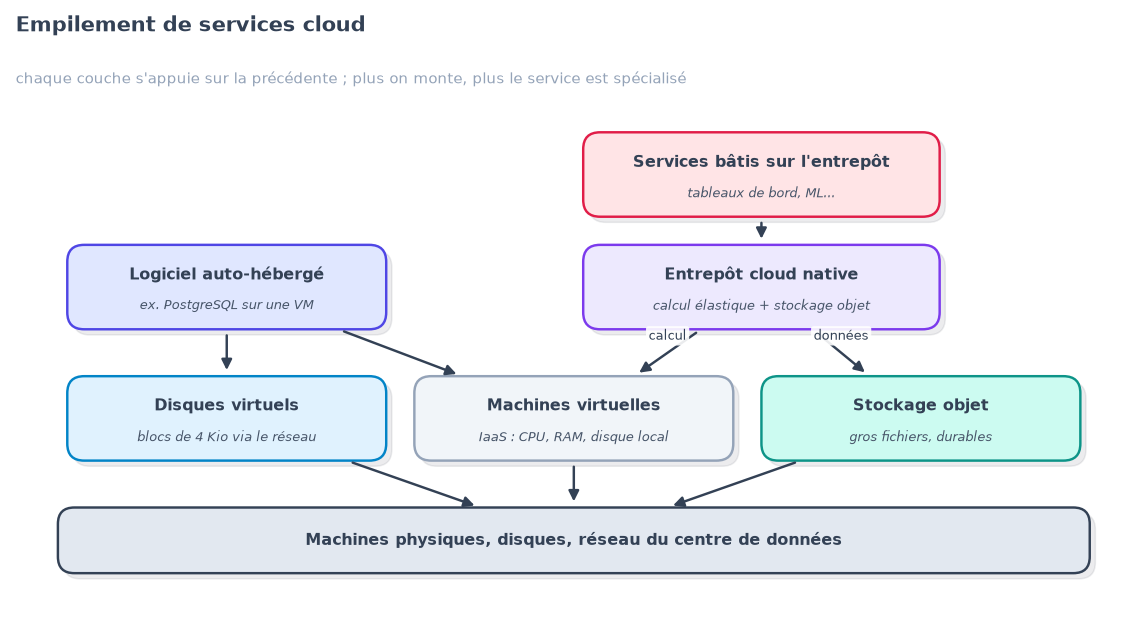

In [6]:
d = Diagram(12, 5.4, title="Empilement de services cloud",
            subtitle="chaque couche s'appuie sur la précédente ; plus on monte, plus le service est spécialisé")
d.box("hw", 6.0, 0.7, "Machines physiques, disques, réseau du centre de données", color=SLATE, w=11.0, h=0.7)
d.box("vm", 6.0, 2.0, "Machines virtuelles", sub="IaaS : CPU, RAM, disque local", color=GRAY, w=3.4)
d.box("blk", 2.3, 2.0, "Disques virtuels", sub="blocs de 4 Kio via le réseau", color=SKY, w=3.4)
d.box("obj", 9.7, 2.0, "Stockage objet", sub="gros fichiers, durables", color=TEAL, w=3.4)
d.box("self", 2.3, 3.4, "Logiciel auto-hébergé", sub="ex. PostgreSQL sur une VM", color=INDIGO, w=3.4)
d.box("dw", 8.0, 3.4, "Entrepôt cloud native", sub="calcul élastique + stockage objet", color=VIOLET, w=3.8)
d.box("up", 8.0, 4.6, "Services bâtis sur l'entrepôt", sub="tableaux de bord, ML...", color=ROSE, w=3.8)
d.arrow("self", "vm"); d.arrow("self", "blk")
d.arrow("dw", "vm", label="calcul"); d.arrow("dw", "obj", label="données")
d.arrow("up", "dw")
for k in ("vm", "blk", "obj"):
    d.arrow(k, "hw")
d.show()

**Ordres de grandeur des couches de stockage.** Ce qui distingue ces couches, c'est leur
**latence d'accès** (temps avant le premier octet) et leur **débit**. Les valeurs
ci-dessous (`ar.STORAGE_TIERS`) sont des ordres de grandeur typiques, très variables
selon le matériel et le fournisseur. Le temps pour lire un objet de taille $s$ vaut
environ $\text{latence} + s / \text{débit}$ : pour les petits objets, la latence domine ;
pour les gros, le débit.

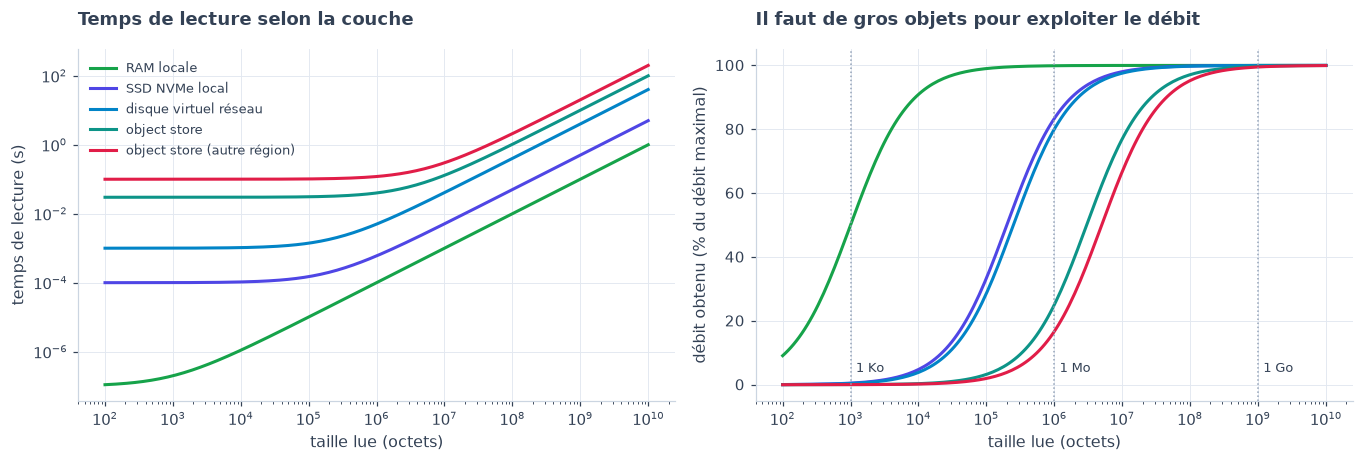

object store : taille pour atteindre 50 % du débit = latence x débit = 3 Mo


In [7]:
sizes = np.logspace(2, 10, 200)              # de 100 octets à 10 Go
tier_colors = [GREEN, INDIGO, SKY, TEAL, ROSE]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))
for (name, (lat, bw)), c in zip(ar.STORAGE_TIERS.items(), tier_colors):
    t = ar.transfer_time(sizes, lat, bw)
    axes[0].loglog(sizes, t, color=c, label=name)
    axes[1].semilogx(sizes, sizes / t / bw * 100, color=c, label=name)
axes[0].set_xlabel("taille lue (octets)"); axes[0].set_ylabel("temps de lecture (s)")
axes[0].set_title("Temps de lecture selon la couche")
axes[0].legend(fontsize=8.5)
axes[1].set_xlabel("taille lue (octets)"); axes[1].set_ylabel("débit obtenu (% du débit maximal)")
axes[1].set_title("Il faut de gros objets pour exploiter le débit")
for x, lab in [(1e3, "1 Ko"), (1e6, "1 Mo"), (1e9, "1 Go")]:
    axes[1].axvline(x, color=GRAY, ls=":", lw=1); axes[1].text(x * 1.2, 4, lab, fontsize=8.5, color=SLATE)
plt.tight_layout(); plt.show()
lat, bw = ar.STORAGE_TIERS["object store"]
print(f"object store : taille pour atteindre 50 % du débit = latence x débit = {lat * bw / 1e6:.0f} Mo")

Un object store a une latence de quelques dizaines de millisecondes : lire un
enregistrement de 100 octets y prend autant de temps que lire 3 Mo. Pour exploiter son
débit, il faut des objets d'au moins quelques mégaoctets. C'est pourquoi le livre
précise que les object stores visent des fichiers de quelques centaines de kilo-octets à
quelques gigaoctets, et que les bases cloud **regroupent** les petites valeurs en gros
blocs pour l'object store, en gérant les petites écritures dans un service à part
(chapitre 4). La facture pousse dans le même sens, car chaque requête est
payante :

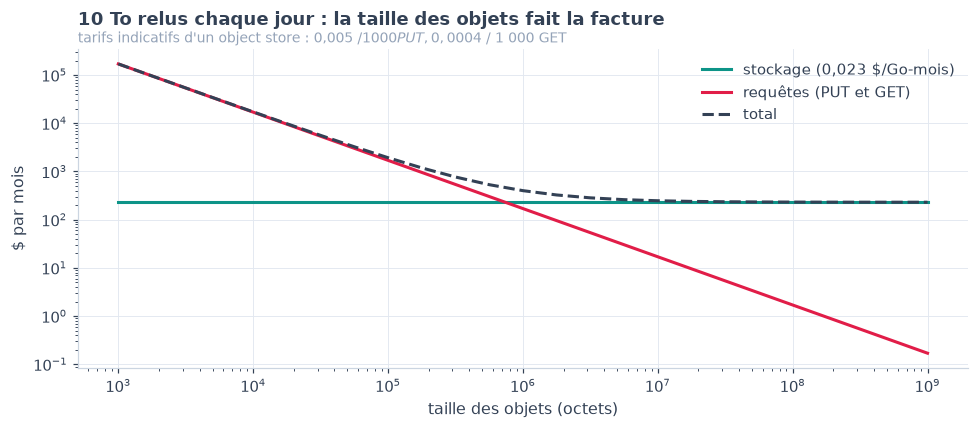

objets de 1 Ko : 170 230 $/mois ; objets de 100 Mo : 232 $/mois


In [8]:
obj_sizes = np.logspace(3, 9, 25)
bills = pd.DataFrame([ar.object_store_monthly_cost(10e12, s, reads_per_month=30) for s in obj_sizes], index=obj_sizes)
fig, ax = plt.subplots(figsize=(9, 4))
ax.loglog(obj_sizes, bills.stockage, color=TEAL, label="stockage (0,023 $/Go-mois)")
ax.loglog(obj_sizes, bills.ecritures + bills.lectures, color=ROSE, label="requêtes (PUT et GET)")
ax.loglog(obj_sizes, bills.total, color=SLATE, ls="--", label="total")
ax.set_xlabel("taille des objets (octets)"); ax.set_ylabel("$ par mois")
ax.set_title("10 To relus chaque jour : la taille des objets fait la facture")
subtitle(ax, "tarifs indicatifs d'un object store : 0,005 $ / 1 000 PUT, 0,0004 $ / 1 000 GET")
ax.legend(); plt.tight_layout(); plt.show()
print(f"objets de 1 Ko : {fmt(bills.total.iloc[0])} $/mois ; objets de 100 Mo : {fmt(bills.total.loc[bills.index >= 1e8].iloc[0])} $/mois")

Avec des objets de 1 Ko, les requêtes coûtent des dizaines de milliers de dollars par mois
alors que le stockage n'en coûte que 230 ; au-delà de quelques mégaoctets par objet, la
facture se réduit au stockage.

> **À retenir.** Le cloud native bâtit des services de haut niveau sur des services de bas
> niveau, à commencer par le stockage objet : durable, élastique, mais à forte latence et
> facturé à la requête. Il faut donc lui confier de **gros** objets, et gérer les petites
> valeurs ailleurs.

## 5. Séparer stockage et calcul (section *Separation of storage and compute*)

**Disques locaux éphémères.** Traditionnellement, un disque est considéré comme durable,
et RAID protège contre la panne d'un disque de la machine. Dans le cloud, une instance a
parfois des disques locaux, mais les systèmes cloud native les traitent comme un **cache
éphémère** : ils deviennent inaccessibles si l'instance tombe en panne ou si on la
remplace par une plus grosse (sur une autre machine physique) pour suivre la charge.
Combien coûte, en temps, le remplacement d'un nœud qui gardait ses données en local ?

In [9]:
data_tb = np.array([0.5, 1, 2, 4, 8, 16])
rows = []
for gbps in (1.0, 10.0):
    rows.append(pd.Series(data_tb * 1e12 * 8 / (gbps * 1e9) / 3600, index=data_tb, name=f"recopie à {gbps:.0f} Gb/s (h)"))
recov = pd.concat(rows, axis=1)
recov.index.name = "données locales du nœud (To)"
recov["nœud sans état + stockage séparé"] = "quelques minutes"
recov

,recopie à 1 Gb/s (h),recopie à 10 Gb/s (h),nœud sans état + stockage séparé
données locales du nœud (To),,,
0.5,1.111,0.111,quelques minutes
1.0,2.222,0.222,quelques minutes
2.0,4.444,0.444,quelques minutes
4.0,8.889,0.889,quelques minutes
8.0,17.778,1.778,quelques minutes
16.0,35.556,3.556,quelques minutes


Un nœud qui détient 4 To en local demande près de 9 heures de recopie à 1 Gb/s (près
d'une heure à 10 Gb/s) avant d'être pleinement opérationnel ; pendant ce temps, la
redondance est réduite. Un nœud de calcul **sans état**, dont les données vivent dans un
service de stockage séparé, redémarre en minutes : il lui suffit de réchauffer son cache.

**Disques virtuels.** Entre les deux, les clouds proposent des **disques virtuels**
détachables (EBS, disques managés, disques persistants) : un service réseau qui émule un
périphérique de blocs de 4 Kio. Ils permettent de faire tourner du logiciel traditionnel
dans le cloud, mais **chaque entrée-sortie devient un appel réseau**, ce qui rend
l'application sensible au moindre hoquet du réseau. Simulons une transaction qui fait 20
entrées-sorties séquentielles : en local, environ 0,1 ms chacune ; sur disque virtuel,
environ 0,6 ms, avec une probabilité de 1 sur 1 000 d'un hoquet de 30 à 80 ms.

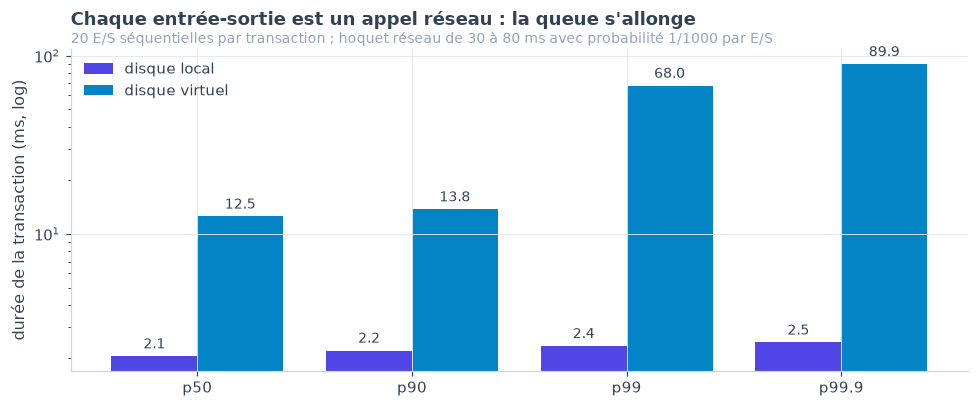

transactions touchées par au moins un hoquet : 2.0% (théorie : 2.0%)


In [10]:
N_TX, N_IO = 100_000, 20
local = rng.lognormal(np.log(0.1), 0.25, (N_TX, N_IO))
virt = rng.lognormal(np.log(0.6), 0.3, (N_TX, N_IO))
glitch = rng.random((N_TX, N_IO)) < 1e-3
virt = virt + glitch * rng.uniform(30, 80, (N_TX, N_IO))
tx = pd.DataFrame({"disque local": local.sum(1), "disque virtuel": virt.sum(1)})
q = tx.quantile([0.5, 0.9, 0.99, 0.999]).T
q.columns = ["p50", "p90", "p99", "p99.9"]

fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(4)
ax.bar(x - 0.2, q.loc["disque local"], 0.4, color=INDIGO, label="disque local")
ax.bar(x + 0.2, q.loc["disque virtuel"], 0.4, color=SKY, label="disque virtuel")
ax.set_yscale("log"); ax.set_xticks(x); ax.set_xticklabels(q.columns)
annotate_bars(ax, "{:.1f}")
ax.set_ylabel("durée de la transaction (ms, log)")
ax.set_title("Chaque entrée-sortie est un appel réseau : la queue s'allonge")
subtitle(ax, "20 E/S séquentielles par transaction ; hoquet réseau de 30 à 80 ms avec probabilité 1/1000 par E/S")
ax.legend(); plt.tight_layout(); plt.show()
print(f"transactions touchées par au moins un hoquet : {glitch.any(1).mean():.1%} (théorie : {1 - 0.999 ** N_IO:.1%})")

La médiane passe de 2 à 12 ms, ce qui est déjà notable ; mais c'est la queue qui
change de nature : avec 20 entrées-sorties, 2 % des transactions rencontrent au moins un
hoquet, et le p99 bondit à plusieurs dizaines de millisecondes. C'est l'amplification de
la latence de queue (chapitre 2) appliquée au stockage. Les services cloud
native évitent donc les disques virtuels et s'appuient sur des services de stockage
spécialisés.

**Un cache local devant l'object store.** Puisque l'object store est lent mais durable, et
le disque local rapide mais éphémère, l'architecture type combine les deux : les données
durables vivent dans l'object store, et chaque nœud de calcul garde en cache local (SSD)
les blocs qu'il lit le plus. Les accès suivent souvent une loi de Zipf (quelques blocs très
demandés) : un petit cache suffit à absorber l'essentiel des lectures.

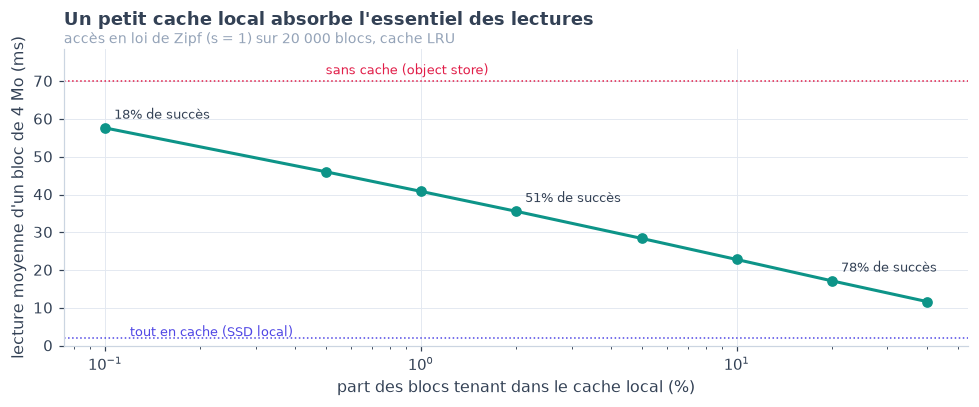

In [11]:
N_BLOCKS = 20_000
trace = ar.zipf_keys(N_BLOCKS, 200_000, s=1.0, seed=3)
lat_ssd, lat_obj = ar.transfer_time(4e6, *ar.STORAGE_TIERS["SSD NVMe local"]), ar.transfer_time(4e6, *ar.STORAGE_TIERS["object store"])
fracs = [0.001, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.4]
res = []
for f in fracs:
    cache = ar.LRUCache(int(f * N_BLOCKS))
    for k in trace:
        cache.get(int(k))
    h_ = cache.hit_ratio
    res.append((f, h_, h_ * lat_ssd + (1 - h_) * lat_obj))
res = pd.DataFrame(res, columns=["fraction en cache", "taux de succès", "lecture moyenne (s)"])
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.semilogx(res["fraction en cache"] * 100, res["lecture moyenne (s)"] * 1e3, "o-", color=TEAL)
for _, r_ in res.iloc[[0, 3, 6]].iterrows():
    ax.annotate(f"{r_['taux de succès']:.0%} de succès", (r_["fraction en cache"] * 100, r_["lecture moyenne (s)"] * 1e3),
                (6, 6), textcoords="offset points", fontsize=8.5)
ax.axhline(lat_obj * 1e3, color=ROSE, ls=":", lw=1); ax.text(0.5, lat_obj * 1e3 + 1, "sans cache (object store)", color=ROSE, fontsize=8.5, va="bottom")
ax.set_ylim(0, lat_obj * 1e3 * 1.12)
ax.axhline(lat_ssd * 1e3, color=INDIGO, ls=":", lw=1); ax.text(0.12, lat_ssd * 1e3 * 1.2, "tout en cache (SSD local)", color=INDIGO, fontsize=8.5)
ax.set_xlabel("part des blocs tenant dans le cache local (%)"); ax.set_ylabel("lecture moyenne d'un bloc de 4 Mo (ms)")
ax.set_title("Un petit cache local absorbe l'essentiel des lectures")
subtitle(ax, "accès en loi de Zipf (s = 1) sur 20 000 blocs, cache LRU")
plt.tight_layout(); plt.show()

Garder 2 % des blocs en cache local donne déjà plus de la moitié de succès et divise par
deux le temps moyen. C'est la **séparation du stockage et du calcul** (on dit aussi
« désagrégation ») : le stockage durable est un service à part (S3 ne fait que stocker
des fichiers), le calcul tourne ailleurs et va chercher les données **par le réseau**
(d'où l'importance du cache, et la discussion du cours 4 sur le coût des transferts).
Elle permet surtout de dimensionner les deux **indépendamment** :

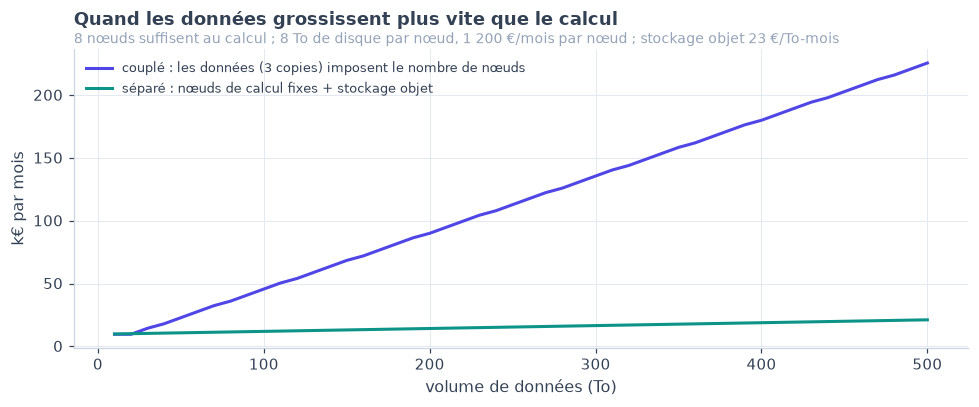

In [12]:
data_tb = np.linspace(10, 500, 50)
cpu_nodes = 8                                                      # besoin de calcul constant
DISK_PER_NODE_TB, NODE_M, OBJ_TB_M = 8, 1200.0, 23.0
coupled = np.maximum(cpu_nodes, np.ceil(data_tb * 3 / DISK_PER_NODE_TB)) * NODE_M   # 3 copies sur les nœuds
disagg = cpu_nodes * NODE_M + data_tb * OBJ_TB_M
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(data_tb, coupled / 1e3, color=INDIGO, label="couplé : les données (3 copies) imposent le nombre de nœuds")
ax.plot(data_tb, disagg / 1e3, color=TEAL, label="séparé : nœuds de calcul fixes + stockage objet")
ax.set_xlabel("volume de données (To)"); ax.set_ylabel("k€ par mois")
ax.set_title("Quand les données grossissent plus vite que le calcul")
subtitle(ax, "8 nœuds suffisent au calcul ; 8 To de disque par nœud, 1 200 €/mois par nœud ; stockage objet 23 €/To-mois")
ax.legend(fontsize=8.5); plt.tight_layout(); plt.show()

Dans une architecture couplée, chaque nœud apporte à la fois du disque et du calcul : si
les données grossissent mais pas les requêtes, on achète du calcul inutile pour avoir du
disque. Séparés, les deux suivent chacun leur propre besoin (et inversement, on peut
allumer cent nœuds de calcul pendant une minute sans toucher au stockage).

> **À retenir.** Dans le cloud, le disque local est un cache éphémère et le disque virtuel
> transforme chaque entrée-sortie en appel réseau. Les systèmes cloud native séparent le
> stockage durable (object store) du calcul (nœuds sans état avec cache local), ce qui
> accélère les reprises et permet de dimensionner chaque ressource indépendamment.

## 6. La multi-location (section *Separation of storage and compute*)

Les systèmes cloud native sont souvent **multi-locataires** (« multitenant ») : au lieu
d'une machine par client, les données et les calculs de plusieurs clients partagent le
même matériel et le même service. Avantages : meilleure utilisation du matériel,
passage à l'échelle et gestion simplifiés. Prix : une ingénierie soignée pour qu'un
client ne dégrade ni la performance ni la sécurité des autres.

**Pourquoi mutualiser rapporte.** Chaque client a une charge en rafales. Dimensionné seul,
il faut prévoir son propre pic ; mutualisés, les pics de clients indépendants tombent
rarement en même temps : on dimensionne pour le pic **de la somme**, bien inférieur à la
somme des pics (c'est le **multiplexage statistique**).

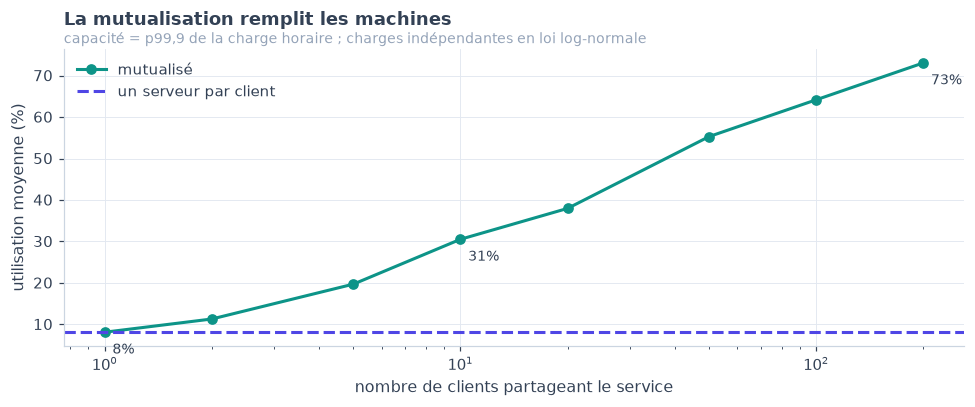

In [13]:
H = 24 * 365
tenants = rng.lognormal(0, 1.0, (200, H))           # charge horaire de 200 clients en rafales
ns = [1, 2, 5, 10, 20, 50, 100, 200]
gain = []
for n in ns:
    sep = np.quantile(tenants[:n], 0.999, axis=1).sum()
    shared = np.quantile(tenants[:n].sum(0), 0.999)
    gain.append((n, sep / shared, tenants[:n].sum(0).mean() / shared))
gain = pd.DataFrame(gain, columns=["clients", "capacité séparée / mutualisée", "utilisation mutualisée"])
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.semilogx(gain.clients, gain["utilisation mutualisée"] * 100, "o-", color=TEAL, label="mutualisé")
ax.axhline(gain["utilisation mutualisée"].iloc[0] * 100, color=INDIGO, ls="--", label="un serveur par client")
ax.set_xlabel("nombre de clients partageant le service"); ax.set_ylabel("utilisation moyenne (%)")
ax.set_title("La mutualisation remplit les machines")
subtitle(ax, "capacité = p99,9 de la charge horaire ; charges indépendantes en loi log-normale")
for _, r_ in gain.iloc[[0, 3, 7]].iterrows():
    ax.annotate(f"{r_['utilisation mutualisée']:.0%}", (r_.clients, r_["utilisation mutualisée"] * 100), (5, -14),
                textcoords="offset points", fontsize=9)
ax.legend(); plt.tight_layout(); plt.show()

Un client seul, dimensionné pour son p99,9, utilise environ 8 % de sa capacité ; deux
cents clients mutualisés, plus de 70 %. C'est le moteur économique du cloud. Le revers est
le **voisin bruyant** : un client qui envoie soudain une rafale ralentit tous les autres.
Simulons un service à 4 serveurs (capacité 1 000 req/s), dix clients à 50 req/s, dont un
qui monte à 1 500 req/s entre 20 et 30 s ; puis la même scène avec un **quota par
client** (seau à jetons, `ar.token_bucket` : 200 req/s, rafale de 50), les requêtes en
excès étant rejetées (le client reçoit « trop de requêtes » et réessaie plus tard).

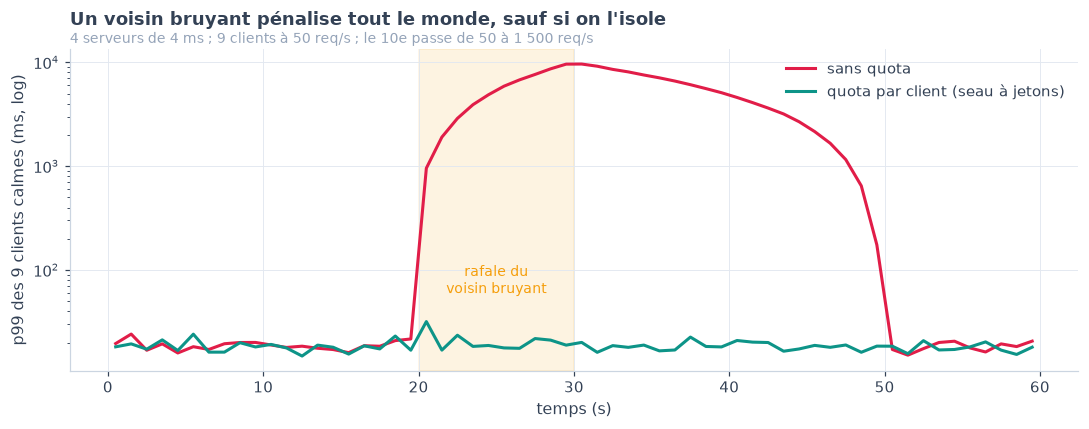

In [14]:
def tenant_arrivals(rate_fn, T, r):
    t, out = 0.0, []
    lam_max = 1500.0
    while t < T:                                   # processus de Poisson non homogène (amincissement)
        t += r.exponential(1 / lam_max)
        if r.random() < rate_fn(t) / lam_max:
            out.append(t)
    return np.array(out)


r = np.random.default_rng(5)
T = 60.0
quiet = [tenant_arrivals(lambda t: 50.0, T, r) for _ in range(9)]
noisy = tenant_arrivals(lambda t: 1500.0 if 20 <= t < 30 else 50.0, T, r)
fig, ax = plt.subplots(figsize=(10, 4))
for label, quota, color in [("sans quota", False, ROSE), ("quota par client (seau à jetons)", True, TEAL)]:
    streams = quiet + [noisy[ar.token_bucket(noisy, 200, 50)] if quota else noisy]
    t_all = np.concatenate(streams)
    who = np.concatenate([np.full(s.size, i) for i, s in enumerate(streams)])
    o = np.argsort(t_all, kind="stable")
    _, end = ar.fifo_servers(t_all[o], r.exponential(0.004, t_all.size), c=4)
    resp = end - t_all[o]
    quiet_mask = who[o] < 9
    s_ = pd.Series(resp[quiet_mask] * 1e3).groupby(np.floor(t_all[o][quiet_mask]).astype(int)).quantile(0.99)
    s_ = s_[s_.index < T]
    ax.semilogy(s_.index + 0.5, s_.values, color=color, label=label)
ax.axvspan(20, 30, color=AMBER, alpha=0.12); ax.text(25, 60, "rafale du\nvoisin bruyant", ha="center", fontsize=9, color=AMBER)
ax.set_xlabel("temps (s)"); ax.set_ylabel("p99 des 9 clients calmes (ms, log)")
ax.set_title("Un voisin bruyant pénalise tout le monde, sauf si on l'isole")
subtitle(ax, "4 serveurs de 4 ms ; 9 clients à 50 req/s ; le 10e passe de 50 à 1 500 req/s")
ax.legend(loc="upper right"); plt.tight_layout(); plt.show()

Sans quota, la rafale sature le service (1 950 req/s pour une capacité de 1 000) : les
clients calmes, qui n'ont rien changé, voient leur p99 passer d'une vingtaine de
millisecondes à près de dix secondes, et la file met encore vingt secondes à se vider
après la rafale. Avec un quota par
client, l'excès du voisin bruyant est rejeté à l'entrée et les autres ne voient presque
rien. L'isolation (quotas, ordonnancement équitable, limites de ressources) est le prix
de la mutualisation ; le partitionnement des clients sur des shards distincts en est une
autre forme (chapitre 7).

> **À retenir.** La multi-location remplit les machines grâce au multiplexage
> statistique, mais exige d'isoler les clients : sans quotas, un voisin bruyant dégrade la
> performance de tous.